In [80]:
from typing import Callable, List, Tuple
from dataclasses import dataclass
import numpy as np
import matplotlib.pyplot as plt
import bisect
import scipy.stats
import time

@dataclass
class BenchmarkConfig:
    initial_x: float = 5.0
    iterations: int = 10000
    proposal_sigma: float = 2.0
    burn_in: int = 1000
    num_seeds: int = 10

config = BenchmarkConfig()

In [81]:
def run_benchmark_with_seeds(method, num_seeds=10, **kwargs):
    """
    Runs your simulated_annealing_optimizer multiple times with different random seeds.
    
    Parameters:
    method: 'mh' or 'arms'.
    num_seeds: The number of independent runs to perform.
    **kwargs: all other arguments to pass to simulated_annealing_optimizer.
    """
    final_values = []
    best_states = []
    all_trajectories = []
    
    # Extract the density function so we can evaluate the best_state and trajectory
    base_log_density = kwargs.get('base_log_density')
    if base_log_density is None:
        raise ValueError("You must pass base_log_density as a keyword argument!")
    
    # We set a master seed first to ensure the sequence of seeds is reproducible
    np.random.seed(67)
    seeds = np.random.randint(0, 100000, size=num_seeds)
    
    print(f"Running {method.upper()} benchmark over {num_seeds} independent seeds...")
    
    for i, seed in enumerate(seeds):
        np.random.seed(seed)
        
        # Call the specific SA optimizer
        best_state, trajectory, temperatures = simulated_annealing_optimizer(method=method, **kwargs)
        
        # Calculate the actual objective log-density from the best state
        best_value = base_log_density(best_state)
        
        final_values.append(best_value)
        best_states.append(best_state)
        
        # We evaluate the density of each state in the trajectory to plot convergence
        trajectory_densities = [base_log_density(state) for state in trajectory]
        all_trajectories.append(trajectory_densities)
        
        print(f"Run {i+1}/{num_seeds} (Seed: {seed:05d}) | Final log-density: {best_value:.6f} | State: {best_state:.6f}")
        
    final_values = np.array(final_values)
    
    # Calculate Statistical Metrics
    mean_value = np.mean(final_values)
    std_value = np.std(final_values)
    median_value = np.median(final_values)
    
    # Find the absolute best run among all seeds
    # We use argmax because higher log-density is better
    best_idx = np.argmax(final_values)
    global_best_value = final_values[best_idx]
    global_best_state = best_states[best_idx]
    
    print("-" * 50)
    print(f"{method.upper()} Statistical Summary:")
    print(f"Mean log-density:   {mean_value:.6f} ± {std_value:.6f}")
    print(f"Median log-density: {median_value:.6f}")
    print(f"Global Best:        {global_best_value:.6f} (Found at state: {global_best_state:.6f})")
    print("-" * 50)
    
    return {
        'mean': mean_value,
        'std': std_value,
        'median': median_value,
        'global_best_value': global_best_value,
        'global_best_state': global_best_state,
        'raw_values': final_values,
        'raw_states': best_states,
        'all_histories': all_trajectories
    }

In [82]:
def plot_statistical_convergence(results_list, labels):
    """
    Plots the average convergence history with standard deviation bands.
    """
    plt.figure(figsize=(10, 6))
    colors = ['blue', 'orange', 'green', 'red']
    
    for i, results in enumerate(results_list):
        # all_histories shape: (num_seeds, num_epochs)
        histories = np.array(results['all_histories'])
        
        # Calculate mean and standard deviation across seeds for each epoch
        mean_history = np.mean(histories, axis=0)
        std_history = np.std(histories, axis=0)
        
        epochs = np.arange(len(mean_history))
        color = colors[i % len(colors)]
        
        # Plot the mean line
        plt.plot(epochs, mean_history, label=f"{labels[i]} (Mean)", color=color, linewidth=2)
        
        # Plot the confidence band (+/- 1 Standard Deviation)
        lower_bound = mean_history - std_history
        upper_bound = mean_history + std_history
        
        plt.fill_between(epochs, lower_bound, upper_bound, color=color, alpha=0.2)
        
    plt.title("Statistical Convergence Comparison (Mean ± 1 Std. Dev.)")
    plt.xlabel("Epoch")
    plt.ylabel("Log Target Density (Higher is Better)")
    plt.legend()
    plt.grid(True, which="both", ls="--", alpha=0.5)
    plt.tight_layout()
    plt.show()

In [83]:
def calculate_ess(samples: np.ndarray) -> float:
    """
    Calculates the Effective Sample Size (ESS) of a 1D Markov chain 
    using the Fast Fourier Transform (FFT) for speed.
    """
    n = len(samples)
    if n < 2:
        return 0.0
        
    var = np.var(samples)
    if var == 0:
        return 1.0 # The chain is completely stuck in one state
        
    # 1. Center the samples
    x_centered = samples - np.mean(samples)
    
    # 2. Pad to the next power of 2 for the FFT to prevent circular correlation
    n_fft = int(2 ** np.ceil(np.log2(2 * n)))
    
    # 3. Compute autocorrelation via FFT
    F_f = np.fft.fft(x_centered, n=n_fft)
    R_xx = np.fft.ifft(F_f * np.conj(F_f))
    R_xx = np.real(R_xx[:n])
    
    # 4. Normalize to get the autocorrelation sequence (rho)
    rho = R_xx / R_xx[0]
    
    # 5. Sum autocorrelations until they drop below 0 (MCMC heuristic)
    sum_rho = 0.0
    for k in range(1, n):
        if rho[k] < 0:
            break
        sum_rho += rho[k]
        
    ess = n / (1.0 + 2.0 * sum_rho)
    return ess

def benchmark_sampler_ess(sampler_func, num_iterations, burn_in=1000, **kwargs):
    """
    Runs a sampler, times it, and calculates ESS and ESS/sec.
    """
    print("Starting sampler benchmark...")
    
    # Start the timer
    start_time = time.time()
    
    # Run the sampler
    samples, rejection_rate = sampler_func(num_iterations=num_iterations, **kwargs)
    
    # Stop the timer
    end_time = time.time()
    elapsed_time = end_time - start_time
    
    # Discard burn-in phase
    valid_samples = samples[config.burn_in:]
    
    # Calculate ESS
    ess = calculate_ess(valid_samples)
    
    # Calculate ESS per second
    ess_per_sec = ess / elapsed_time if elapsed_time > 0 else 0
    
    print("-" * 50)
    print(f"Sampling Efficiency Summary (ESS / Second)")
    print("-" * 50)
    print(f"Total Iterations:  {num_iterations:,}")
    print(f"Burn-in Discarded: {burn_in:,}")
    print(f"Acceptance Rate:   {(1 - rejection_rate)*100:.2f}%")
    print(f"Elapsed Time:      {elapsed_time:.4f} seconds")
    print(f"Effective Samples: {ess:.2f} (out of {len(valid_samples):,})")
    print(f"ESS / Second:      {ess_per_sec:.2f}")
    print("-" * 50)
    
    return ess, ess_per_sec, elapsed_time, valid_samples

### Random Walk Metropolitan Hastings (RWMH)

In [84]:
def gaussian_proposal(x_t, sigma):
    """
    Draws a candidate state x_star from a Gaussian perturbation 
    centered at the current state x_t with standard deviation sigma.
    """
    # Generate the Gaussian perturbation epsilon ~ N(0, sigma^2)
    epsilon = np.random.normal(loc=0.0, scale=sigma)
    
    # Calculate the new candidate state
    x_star = x_t + epsilon
    
    return x_star

In [85]:
def log_acceptance_probability(x_t, x_star, log_target_density):
    """
    Calculates the acceptance probability alpha in log-space 
    for a symmetric proposal Metropolis-Hastings step.
    
    Parameters:
    x_t: The current state.
    x_star: The proposed candidate state.
    log_target_density: A function that returns the unnormalized log-probability 
                        density h(x) = ln(pi(x)) for a given state x.
                        
    Returns:
    alpha: The probability of accepting the candidate state (between 0 and 1).
    """
    # Evaluate the log-target density at the current and candidate states
    log_pi_current = log_target_density(x_t)
    log_pi_candidate = log_target_density(x_star)
    
    # Calculate the log-acceptance ratio
    # alpha = min(1, pi(x*)/pi(x_t)) becomes ln(alpha) = min(0, ln(pi(x*)) - ln(pi(x_t)))
    log_alpha = min(0.0, log_pi_candidate - log_pi_current)
    
    # Exponentiate to return the actual probability alpha
    alpha = np.exp(log_alpha)
    
    return alpha

In [86]:
def random_walk_mh(initial_state, num_iterations, sigma, log_target_density):
    """
    Executes the Random Walk Metropolis-Hastings algorithm.
    
    Parameters:
    initial_state: The starting value for the Markov chain.
    num_iterations: The total number of steps to run the chain.
    sigma: The standard deviation for the Gaussian proposal distribution.
    log_target_density: The unnormalized log-probability density function h(x).
    
    Returns:
    samples: A numpy array of all states visited by the chain.
    rejection_rate: The proportion of proposed candidates that were rejected.
    """
    # Initialize an array to hold our samples. We make it size (num_iterations + 1)
    # so we can store the initial state at index 0.
    samples = np.zeros(num_iterations + 1)
    samples[0] = initial_state
    
    current_state = initial_state
    rejected_count = 0
    
    # The main Markov chain loop
    for t in range(1, num_iterations + 1):
        # Step A: Propose a new candidate state
        candidate_state = gaussian_proposal(current_state, sigma)
        
        # Step B: Calculate the acceptance probability alpha
        alpha = log_acceptance_probability(current_state, candidate_state, log_target_density)
        
        # Step C: The Acceptance/Rejection Check
        # We draw a random uniform number u between 0 and 1. 
        # If u is less than or equal to alpha, we accept the move.
        u = np.random.uniform(0.0, 1.0)
        
        if u <= alpha:
            # Move accepted: update the current state
            current_state = candidate_state
        else:
            # Move rejected: stay at the current state and increment our rejection counter
            rejected_count += 1
            
        # Step D: Log the state (whether we moved or stayed still)
        samples[t] = current_state
        
    # Calculate final statistics
    rejection_rate = rejected_count / num_iterations
    
    return samples, rejection_rate

Running Random Walk MH...
Sampling complete!
Rejection Rate: 50.12%
Acceptance Rate: 49.88%


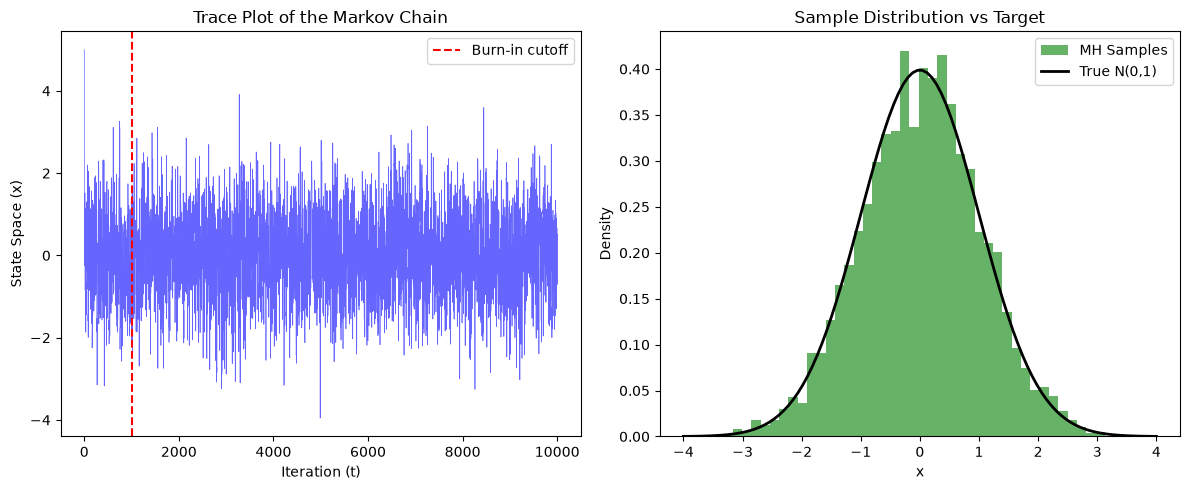

In [87]:
def standard_normal_log_density(x):
    return -0.5 * (x ** 2)

# Algorithm parameters
initial_x = 5.0          # Starting far from the true mean (0) to see it converge
iterations = 10000       # Number of steps
proposal_sigma = 2.0     # Standard deviation of our proposal jump

# Run the algorithm
print("Running Random Walk MH...")
samples, rejection_rate = random_walk_mh(
    initial_state=initial_x, 
    num_iterations=iterations, 
    sigma=proposal_sigma, 
    log_target_density=standard_normal_log_density
)

# Print diagnostics
print(f"Sampling complete!")
print(f"Rejection Rate: {rejection_rate * 100:.2f}%")
print(f"Acceptance Rate: {(1 - rejection_rate) * 100:.2f}%")

# Visualize the results
# We discard the first 1000 samples as "burn-in" to let the chain converge
burn_in = 1000
valid_samples = samples[burn_in:]

plt.figure(figsize=(12, 5))

# Plot 1: Trace plot to check for convergence and mixing
plt.subplot(1, 2, 1)
plt.plot(samples, alpha=0.6, color='blue', linewidth=0.5)
plt.axvline(x=burn_in, color='red', linestyle='--', label='Burn-in cutoff')
plt.title("Trace Plot of the Markov Chain")
plt.xlabel("Iteration (t)")
plt.ylabel("State Space (x)")
plt.legend()

# Plot 2: Histogram of samples vs True Target Density
plt.subplot(1, 2, 2)
plt.hist(valid_samples, bins=50, density=True, alpha=0.6, color='green', label='MH Samples')

# Plot the true theoretical curve over it
x_axis = np.linspace(-4, 4, 100)
true_density = (1 / np.sqrt(2 * np.pi)) * np.exp(-0.5 * x_axis**2)
plt.plot(x_axis, true_density, color='black', linewidth=2, label='True N(0,1)')

plt.title("Sample Distribution vs Target")
plt.xlabel("x")
plt.ylabel("Density")
plt.legend()

plt.tight_layout()
plt.show()

### Adaptive Rejection Metropolis Sampling (ARMS)

In [88]:
def initialize_abscissae(x_init, num_points=5, spread=2.0):
    """
    Selects an initial sorted set of support points (abscissae) S_0.
    
    Parameters:
    x_init: The starting state of the Markov chain.
    num_points: The number of initial support points to generate.
    spread: How wide the initial points should be spread around x_init.
    
    Returns:
    S: A sorted Python list of initial support points.
    """
    if num_points < 2:
        raise ValueError("We need at least 2 points to form a secant line.")
        
    half_spread = spread / 2.0
    start = x_init - half_spread
    end = x_init + half_spread
    
    # Generate evenly spaced points and convert to a list so we can 
    # use the .append() or .insert() methods later in ARMS when adding rejected points.
    S = np.linspace(start, end, num_points).tolist()
    
    return S

def evaluate_hull(x, S, log_target_density):
    """
    Evaluates the piecewise linear upper hull e_k(x) at a given candidate point x.
    
    Parameters:
    x: The candidate point where we want to evaluate the hull.
    S: A sorted list or array of current support points.
    log_target_density: The function h(x) = ln(pi(x)).
    
    Returns:
    e_k: The value of the upper hull at x.
    """
    n = len(S)
    if n < 2:
        raise ValueError("At least two support points are required to build the hull.")
        
    # np.searchsorted finds the index where 'x' should be inserted into 'S' 
    # to maintain the sorted order. This tells us exactly which interval x is in.
    idx = np.searchsorted(S, x)
    
    # Condition 1: Left Tail Extrapolation (x is smaller than our smallest support point)
    if idx == 0:
        i, j = 0, 1
        
    # Condition 2: Right Tail Extrapolation (x is larger than our largest support point)
    elif idx == n:
        i, j = n - 2, n - 1
        
    # Condition 3: Interpolation (x is between two support points)
    else:
        i, j = idx - 1, idx
        
    # Extract the two points that will form our secant line
    x_i, x_j = S[i], S[j]
    
    # Evaluate the log-target density at these points
    h_i = log_target_density(x_i)
    h_j = log_target_density(x_j)
    
    # Calculate the slope: (h(x_{i+1}) - h(x_i)) / (x_{i+1} - x_i)
    slope = (h_j - h_i) / (x_j - x_i)
    
    # Apply the secant line formula
    e_k = h_i + slope * (x - x_i)
    
    return e_k

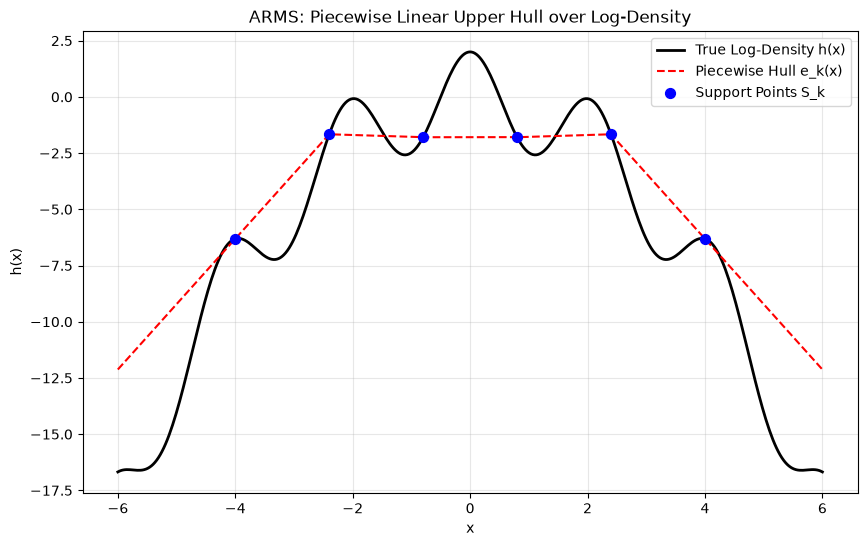

In [89]:
# Define a multimodal target (similar to a 1D slice of Ackley or Rastrigin)
def test_log_density(x):
    # h(x) = -0.5 * x^2 + 2 * cos(3x) 
    return -0.5 * (x**2) + 2 * np.cos(3 * x)

# 1. Initialize 6 support points spread across the landscape
S = initialize_abscissae(x_init=0.0, num_points=6, spread=8.0)

# 2. Generate points for plotting the true curve and the hull
x_plot = np.linspace(-6, 6, 400)
true_h = test_log_density(x_plot)

# 3. Evaluate the hull e_k(x) for every point in x_plot
hull_e_k = [evaluate_hull(x, S, test_log_density) for x in x_plot]

# 4. Plot the results
plt.figure(figsize=(10, 6))
plt.plot(x_plot, true_h, label="True Log-Density h(x)", color="black", linewidth=2)
plt.plot(x_plot, hull_e_k, label="Piecewise Hull e_k(x)", color="red", linestyle="--")

# Mark the support points
S_y = [test_log_density(x) for x in S]
plt.scatter(S, S_y, color="blue", zorder=5, s=50, label="Support Points S_k")

plt.title("ARMS: Piecewise Linear Upper Hull over Log-Density")
plt.xlabel("x")
plt.ylabel("h(x)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [90]:
def sample_from_hull(S, log_target_density, evaluate_hull, bounds=(-20, 20), **kwargs):
    """
    Exact analytical hull sampling implementation. 
    Draws a candidate x* from the normalized envelope exp(e_k(x)) using exact 
    piecewise integration and inverse transform sampling. 
    This natively provides infinite spatial resolution.
    """
    n = len(S)
    
    # 1. Evaluate log density at all support points
    h_S = np.array([log_target_density(x) for x in S])
    
    # 2. Compute slopes between adjacent support points
    slopes = np.zeros(n - 1)
    for i in range(n - 1):
        dx = S[i+1] - S[i]
        if dx == 0:
            slopes[i] = 0.0
        else:
            slopes[i] = (h_S[i+1] - h_S[i]) / dx
            
    # 3. Construct piecewise intervals (A, B, e_A, m)
    intervals = []
    L, U = bounds
    
    # Left tail
    if L < S[0]:
        m = slopes[0]
        e_A = h_S[0] + m * (L - S[0])
        intervals.append((L, S[0], e_A, m))
        
    # Middle intervals
    for i in range(n - 1):
        intervals.append((S[i], S[i+1], h_S[i], slopes[i]))
        
    # Right tail
    if U > S[-1]:
        m = slopes[-1]
        e_A = h_S[-1]
        intervals.append((S[-1], U, e_A, m))
        
    # 4. Calculate global max of the envelope to prevent exp() overflow
    endpoints_e = [inv[2] for inv in intervals]
    final_inv = intervals[-1]
    final_e_B = final_inv[2] + final_inv[3] * (final_inv[1] - final_inv[0])
    endpoints_e.append(final_e_B)
    max_e = np.max(endpoints_e)
    
    # 5. Calculate exact areas (unnormalized probabilities) for each interval
    areas = np.zeros(len(intervals))
    for idx, (A, B, e_A, m) in enumerate(intervals):
        c_start = e_A - max_e
        delta = B - A
        c_end = c_start + m * delta
        
        if abs(m) < 1e-8:
            areas[idx] = np.exp(c_start) * delta
        else:
            # W = (exp(c_end) - exp(c_start)) / m
            areas[idx] = (np.exp(c_end) - np.exp(c_start)) / m
            
    # 6. Normalize to create a discrete probability distribution
    total_area = np.sum(areas)
    if total_area <= 0 or not np.isfinite(total_area):
        probs = np.ones(len(intervals)) / len(intervals)
    else:
        probs = areas / total_area
        probs = probs / np.sum(probs) # Ensure strict sum to 1.0
        
    # 7. Select an interval based on exact probabilities
    chosen_idx = np.random.choice(len(intervals), p=probs)
    A, B, e_A, m = intervals[chosen_idx]
    
    # 8. Exact Analytical Inverse Transform Sampling
    u = np.random.uniform(0.0, 1.0)
    delta = B - A
    
    if abs(m) < 1e-8:
        x_star = A + u * delta
    elif abs(m * delta) < 50.0:
        # Standard analytical inversion for moderate slopes
        x_star = A + (1.0 / m) * np.log1p(u * np.expm1(m * delta))
    else:
        # Log-Sum-Exp trick to prevent overflow on extreme slopes
        if u == 0.0:
            x_star = A
        elif u == 1.0:
            x_star = B
        else:
            v1 = np.log(1.0 - u)
            v2 = np.log(u) + m * delta
            vmax = max(v1, v2)
            log_term = vmax + np.log(np.exp(v1 - vmax) + np.exp(v2 - vmax))
            x_star = A + log_term / m
            
    # Clip to absolute bounds to handle microscopic floating point drift
    return np.clip(x_star, L, U)

In [91]:
def stage_1_ars_check(x_star, log_target_density, e_k_star):
    """
    Performs the first acceptance check (ARS step) in log-space.
    Returns True if passed, False if rejected.
    """
    h_star = log_target_density(x_star)
    
    # log(alpha_1) = min(0, h(x*) - e_k(x*))
    log_alpha_1 = min(0.0, h_star - e_k_star)
    alpha_1 = np.exp(log_alpha_1)
    
    u = np.random.uniform(0.0, 1.0)
    
    return u <= alpha_1

In [92]:
def update_hull(S, x_star):
    """
    Adds x* to the support points S_k while maintaining sorted order.
    Because evaluate_hull dynamically computes secants based on S, 
    simply inserting the point inherently 'recalculates' the envelope.
    """
    bisect.insort(S, x_star)
    return S

In [93]:
def stage_2_metropolis_check(x_t, x_star, S, log_target_density, evaluate_hull):
    """
    Performs the second acceptance check (Metropolis correction) in log-space,
    using the Gilks (1995) detailed balance equation.
    """
    h_t = log_target_density(x_t)
    h_star = log_target_density(x_star)
    
    e_k_t = evaluate_hull(x_t, S, log_target_density)
    e_k_star = evaluate_hull(x_star, S, log_target_density)
    
    # 1. Calculate log weights w(x) = h(x) - e_k(x)
    log_w_t = h_t - e_k_t
    log_w_star = h_star - e_k_star
    
    # 2. Gilks (1995) ARMS Metropolis Ratio 
    log_alpha_2 = min(0.0, log_w_star + min(0.0, log_w_t) - log_w_t - min(0.0, log_w_star))
    alpha_2 = np.exp(log_alpha_2)
    
    u = np.random.uniform(0.0, 1.0)
    
    return u <= alpha_2

In [94]:
def generate_arms_candidate(
    x_t: float, 
    S: List[float], 
    log_target_density: Callable[[float], float], 
    evaluate_hull: Callable[[float, List[float], Callable], float], 
    bounds: Tuple[float, float] = (-10.0, 10.0),
    max_retries: int = 1000
) -> Tuple[float, List[float]]:
    """
    Handles the continuous drawing, stage checks, and hull updates 
    required to generate one valid step in the ARMS Markov chain.
    """
    retries = 0
    while retries < max_retries:
        # Draw candidate x* from the envelope exp(e_k(x)) with dynamic bounds
        x_star = sample_from_hull(S, log_target_density, evaluate_hull, bounds=bounds)
        e_k_star = evaluate_hull(x_star, S, log_target_density)
        
        # Perform the Stage 1 ARS Check
        passed_stage_1 = stage_1_ars_check(x_star, log_target_density, e_k_star)
        
        if not passed_stage_1:
            # Stage 1 Failed: Update the support points to tighten the hull
            S = update_hull(S, x_star)
            retries += 1
            continue 
            
        else:
            # Stage 1 Passed: Proceed to Stage 2 Metropolis Correction
            passed_stage_2 = stage_2_metropolis_check(
                x_t, x_star, S, log_target_density, evaluate_hull
            )
            
            final_state = x_star if passed_stage_2 else x_t
            return final_state, S
            
    # Safeguard triggered
    print(f"Warning: ARMS candidate generation hit max_retries ({max_retries}). Returning current state.")
    return x_t, S
        

Testing static ARMS...


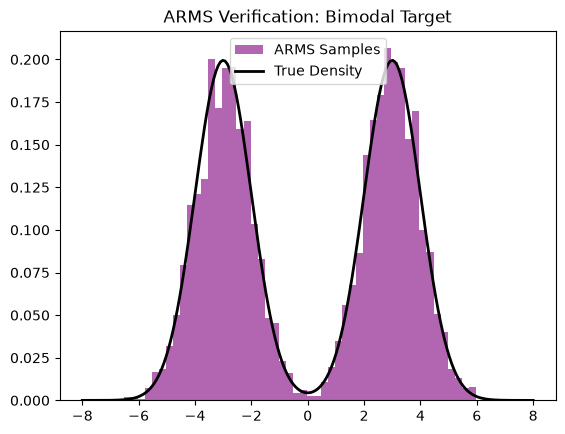

In [95]:
def test_static_arms():
    print("Testing static ARMS...")
    # A simple bimodal target: a mix of N(-3, 1) and N(3, 1)
    def bimodal_log_density(x):
        # We avoid log(0) by adding a tiny epsilon
        p1 = np.exp(-0.5 * (x + 3)**2)
        p2 = np.exp(-0.5 * (x - 3)**2)
        return np.log(p1 + p2 + 1e-10)

    num_samples = 5000
    samples = np.zeros(num_samples)
    
    # Initialize
    current_x = 0.0
    S = initialize_abscissae(current_x, num_points=5, spread=10.0)
    samples[0] = current_x
    
    # Run ARMS
    for i in range(1, num_samples):
        current_x, S = generate_arms_candidate(current_x, S, bimodal_log_density, evaluate_hull)
        samples[i] = current_x
    
    # Plotting to verify
    plt.hist(samples[500:], bins=50, density=True, alpha=0.6, color='purple', label="ARMS Samples")
    x_axis = np.linspace(-8, 8, 200)
    # The true unnormalized density is just the exponentiated log-density
    true_density = np.exp([bimodal_log_density(x) for x in x_axis])
    # Normalize for visual comparison
    true_density /= np.trapezoid(true_density, x_axis) 
    
    plt.plot(x_axis, true_density, 'k-', linewidth=2, label="True Density")
    plt.title("ARMS Verification: Bimodal Target")
    plt.legend()
    plt.show()

test_static_arms()

In [96]:
def arms_sampler(num_iterations, initial_state, log_target_density, arms_points=5, arms_spread=4.0):
    samples = np.zeros(num_iterations + 1)
    samples[0] = initial_state
    current_state = initial_state
    
    S = initialize_abscissae(current_state, num_points=arms_points, spread=arms_spread)
    
    for t in range(1, num_iterations + 1):
        current_state, S = generate_arms_candidate(
            current_state, S, log_target_density, evaluate_hull, bounds=(-20, 20)
        )
        samples[t] = current_state
        
    return samples, 0.0 # ARMS rejection is internal, so we return a dummy rate

### Simulated Annealing (SA)

In [97]:
def create_tempered_log_density(log_target_density, T):
    """
    Returns a dynamically tempered log-density function h_T(x) = h(x) / T.
    """
    def tempered_density(x):
        return log_target_density(x) / T
    return tempered_density

In [98]:
def geometric_cooling(T_current, eta=0.95):
    """
    Multiplies the current temperature by a constant decay rate eta.
    """
    return T_current * eta

def logarithmic_cooling(T_initial, epoch, c=1.0):
    """
    Decreases temperature logarithmically. 
    Epoch must be >= 1.
    """
    return (c * T_initial) / np.log(1 + epoch)

In [99]:
def simulated_annealing_optimizer(
    method, initial_state, base_log_density, 
    num_epochs, steps_per_epoch, T_init, 
    cooling_type='geometric', eta=0.95, c=1.0, 
    mh_sigma=1.0, arms_points=5, arms_spread=4.0,
    search_bounds=(-20, 20)
):
    """
    Runs Simulated Annealing optimization using either MH or ARMS.
    """
    current_state = initial_state
    best_state = current_state
    best_density = base_log_density(current_state)
    
    T_current = T_init
    trajectory = np.zeros(num_epochs)
    temperatures = np.zeros(num_epochs)
    
    for epoch in range(num_epochs):
        temperatures[epoch] = T_current
        tempered_target = create_tempered_log_density(base_log_density, T_current)
        
        if method == 'mh':
            for _ in range(steps_per_epoch):
                candidate = current_state + np.random.normal(0, mh_sigma)
                alpha = log_acceptance_probability(current_state, candidate, tempered_target)
                if np.random.uniform(0, 1) <= alpha:
                    current_state = candidate
                
                # Check for optimum inside the inner loop
                current_density = base_log_density(current_state)
                if current_density > best_density:
                    best_density = current_density
                    best_state = current_state
                    
        elif method == 'arms':
            S = initialize_abscissae(current_state, num_points=arms_points, spread=arms_spread)
            
            for _ in range(steps_per_epoch):
                current_state, S = generate_arms_candidate(
                    current_state, S, tempered_target, evaluate_hull, bounds=search_bounds
                )
                
                # Check for optimum inside the inner loop
                current_density = base_log_density(current_state)
                if current_density > best_density:
                    best_density = current_density
                    best_state = current_state
        
        # Record the state at the end of the epoch for the trajectory path
        trajectory[epoch] = current_state
        
        # Lower the temperature for the next epoch
        if cooling_type == 'geometric':
            T_current = geometric_cooling(T_current, eta)
        elif cooling_type == 'logarithmic':
            T_current = logarithmic_cooling(T_init, epoch + 1, c)
            
    return best_state, trajectory, temperatures

Running MH + SA...
Running ARMS + SA...


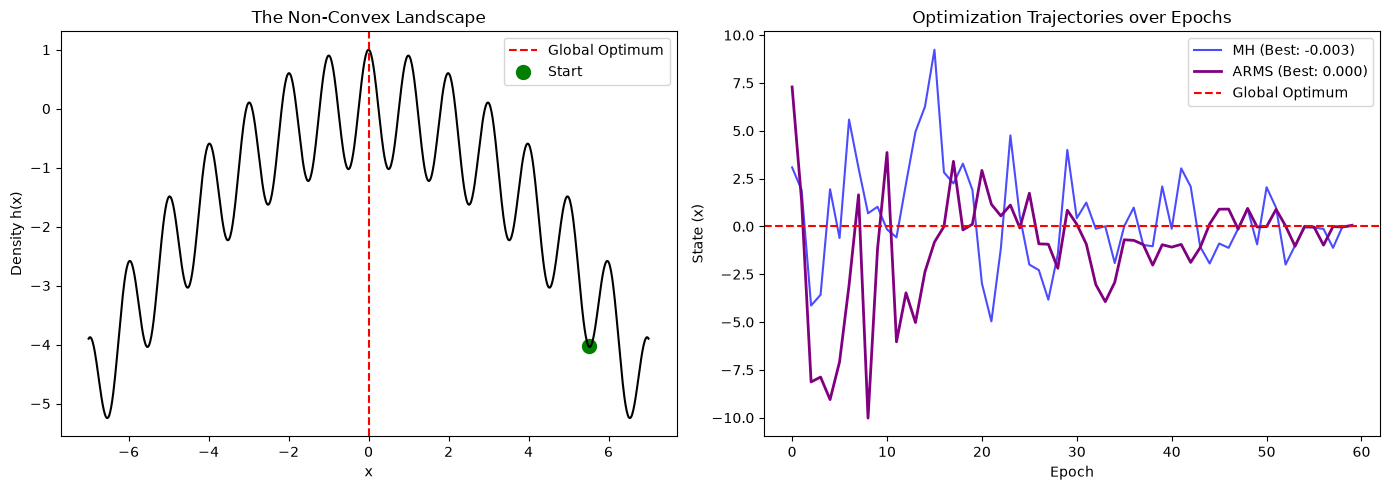

In [100]:
def run_optimization_benchmark():
    # A highly non-convex landscape. Global max is at x = 0.
    def non_convex_landscape(x):
        return -0.1 * (x**2) + np.cos(2 * np.pi * x)

    # Global SA parameters
    initial_x = 5.5 # Start far from the global max (0.0), stuck behind local maxima
    T_init = 10.0
    epochs = 60
    steps = 20
    
    print("Running MH + SA...")
    mh_best, mh_traj, temps = simulated_annealing_optimizer(
        method='mh', initial_state=initial_x, base_log_density=non_convex_landscape,
        num_epochs=epochs, steps_per_epoch=steps, T_init=T_init,
        cooling_type='geometric', eta=0.92, mh_sigma=1.0
    )
    
    print("Running ARMS + SA...")
    arms_best, arms_traj, _ = simulated_annealing_optimizer(
        method='arms', initial_state=initial_x, base_log_density=non_convex_landscape,
        num_epochs=epochs, steps_per_epoch=steps, T_init=T_init,
        cooling_type='geometric', eta=0.92, arms_points=5, arms_spread=2.0
    )
    
    # Visualization
    plt.figure(figsize=(14, 5))
    
    # Plot 1: The Landscape
    plt.subplot(1, 2, 1)
    x_axis = np.linspace(-7, 7, 1000)
    plt.plot(x_axis, non_convex_landscape(x_axis), color='black')
    plt.axvline(x=0, color='red', linestyle='--', label='Global Optimum')
    plt.scatter([initial_x], [non_convex_landscape(initial_x)], color='green', s=100, label='Start')
    plt.title("The Non-Convex Landscape")
    plt.xlabel("x")
    plt.ylabel("Density h(x)")
    plt.legend()
    
    # Plot 2: Convergence Trajectories
    plt.subplot(1, 2, 2)
    plt.plot(mh_traj, label=f"MH (Best: {mh_best:.3f})", color='blue', alpha=0.7)
    plt.plot(arms_traj, label=f"ARMS (Best: {arms_best:.3f})", color='purple', linewidth=2)
    plt.axhline(y=0, color='red', linestyle='--', label='Global Optimum')
    
    plt.title("Optimization Trajectories over Epochs")
    plt.xlabel("Epoch")
    plt.ylabel("State (x)")
    plt.legend()
    
    plt.tight_layout()
    plt.show()

# Run the benchmark
run_optimization_benchmark()

### Target Functions

In [101]:
def rastrigin_log_density(x, A=10.0):
    """
    Computes the inverted Rastrigin function to act as a log-density target.
    
    Parameters:
    x: A scalar or numpy array representing the state.
    A: The amplitude of the cosine modulation (standard is 10.0).
    """
    # Ensure x is a numpy array for vectorized operations
    x = np.atleast_1d(x)
    n = len(x)
    
    # Calculate the standard Rastrigin output
    f_x = A * n + np.sum(x**2 - A * np.cos(2 * np.pi * x))
    
    # We return -f_x so the global minimum at 0 becomes the global maximum
    return -f_x

In [102]:
def ackley_log_density(x, a=20.0, b=0.2, c=2.0 * np.pi):
    """
    Computes the inverted Ackley function to act as a log-density target.
    """
    x = np.atleast_1d(x)
    n = len(x)
    
    # Term 1: The exponential of the square root of the sum of squares
    sum_sq = np.sum(x**2)
    term1 = -a * np.exp(-b * np.sqrt(sum_sq / n))
    
    # Term 2: The exponential of the sum of cosines
    sum_cos = np.sum(np.cos(c * x))
    term2 = -np.exp(sum_cos / n)
    
    # Combine according to the formula
    f_x = term1 + term2 + a + np.e
    
    # Return the negative to create a peak for maximization
    return -f_x

In [103]:
def gaussian_mixture_probability(x, weights, means, std_devs):
    """
    Computes the raw probability density pi(x) for a 1D Mixture of Gaussians.
    
    Parameters:
    weights: A list of probabilities w_k that must sum to 1.
    means: A list of means mu_k for each component.
    std_devs: A list of standard deviations sigma_k for each component.
    """
    # Initialize the total probability to 0
    prob = 0.0
    
    # Iterate through each component and add its weighted contribution
    for w, mu, sigma in zip(weights, means, std_devs):
        # scipy.stats.norm.pdf calculates the standard Gaussian density
        prob += w * scipy.stats.norm.pdf(x, loc=mu, scale=sigma)
        
    return prob

In [104]:
def make_log_density(probability_function):
    """
    A wrapper function that converts a raw probability function pi(x) 
    into a mathematically stable log-density function h(x) = ln(pi(x)).
    """
    def log_density(x, *args, **kwargs):
        # Calculate the raw probability
        prob = probability_function(x, *args, **kwargs)
        
        # Add a tiny constant (1e-12) before taking the logarithm.
        # This prevents catastrophic MathDomainErrors if the probability 
        # drops perfectly to 0.0 in the deep tails of the distribution.
        return np.log(prob + 1e-12)
        
    return log_density

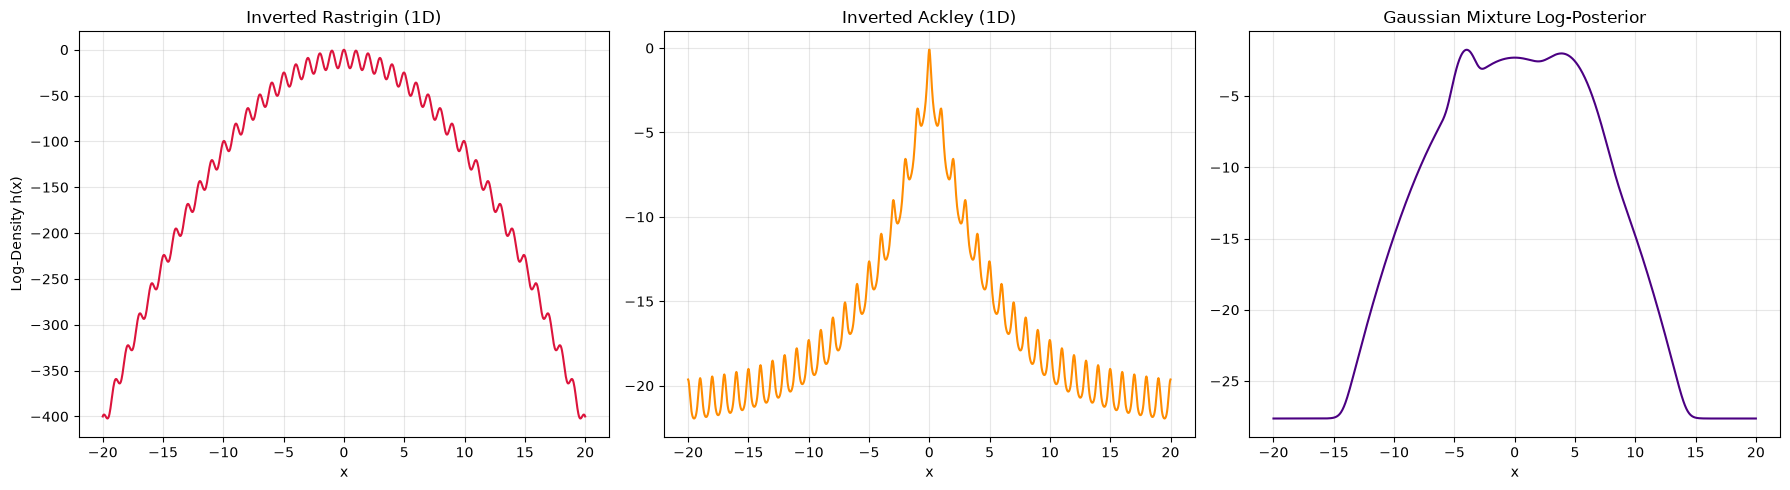

In [105]:
def run_landscape_tests():
    """
    Evaluates and plots the 1D slices of the target log-density functions
    to verify they have the correct peaks and shapes for maximization.
    """
    # Create a high-resolution grid of x values to evaluate
    x_axis = np.linspace(-20, 20, 1000)
    
    # 1. Evaluate Rastrigin
    # We use a list comprehension because the function treats an array input 
    # as a single high-dimensional coordinate, but we want 1000 1D coordinates.
    rastrigin_y = [rastrigin_log_density(x) for x in x_axis]
    
    # 2. Evaluate Ackley
    ackley_y = [ackley_log_density(x) for x in x_axis]
    
    # 3. Evaluate the Gaussian Mixture
    weights = [0.2, 0.5, 0.3]
    means = [-4.0, 0.0, 4.0]
    std_devs = [0.5, 2.0, 1.0]
    
    def frozen_mixture(x):
        return gaussian_mixture_probability(x, weights, means, std_devs)
        
    mixture_log_density = make_log_density(frozen_mixture)
    mixture_y = [mixture_log_density(x) for x in x_axis]

    # Plotting
    fig, axs = plt.subplots(1, 3, figsize=(18, 5))
    
    # Plot 1: Rastrigin
    axs[0].plot(x_axis, rastrigin_y, color='crimson')
    axs[0].set_title("Inverted Rastrigin (1D)")
    axs[0].set_xlabel("x")
    axs[0].set_ylabel("Log-Density h(x)")
    axs[0].grid(True, alpha=0.3)
    
    # Plot 2: Ackley
    axs[1].plot(x_axis, ackley_y, color='darkorange')
    axs[1].set_title("Inverted Ackley (1D)")
    axs[1].set_xlabel("x")
    axs[1].grid(True, alpha=0.3)
    
    # Plot 3: Gaussian Mixture
    axs[2].plot(x_axis, mixture_y, color='indigo')
    axs[2].set_title("Gaussian Mixture Log-Posterior")
    axs[2].set_xlabel("x")
    axs[2].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

run_landscape_tests()

### Benchmarking

In [106]:
def compute_autocorrelation(samples, max_lag):
    """
    Computes the autocorrelation of a 1D array of samples up to a specified maximum lag.
    
    Parameters:
    samples: A 1D numpy array of MCMC samples.
    max_lag: The maximum number of time steps (lags) to compute correlation for.
    
    Returns:
    lags: An array of lag indices (0 to max_lag).
    autocorr: The autocorrelation values corresponding to each lag.
    """
    # 1. Center the samples by subtracting the mean
    centered_samples = samples - np.mean(samples)
    
    # 2. Compute the variance to normalize the results (lag 0 autocorrelation is always 1)
    variance = np.var(samples)
    
    if variance == 0:
        # Prevent division by zero if the chain never moves
        return np.arange(max_lag + 1), np.zeros(max_lag + 1)
    
    # 3. Use numpy's correlate function to find the full cross-correlation of the signal with itself
    # 'full' mode returns correlations for all possible overlaps. 
    # We slice [len(samples)-1:] to get only the positive lags starting from 0.
    full_corr = np.correlate(centered_samples, centered_samples, mode='full')
    pos_corr = full_corr[len(samples) - 1:]
    
    # 4. Normalize by the variance and the number of overlapping points at each lag
    N = len(samples)
    autocorr = pos_corr[:max_lag + 1] / (variance * (N - np.arange(max_lag + 1)))
    
    lags = np.arange(max_lag + 1)
    return lags, autocorr

In [107]:
def gelman_rubin_statistic(chains):
    """
    Computes the Gelman-Rubin convergence diagnostic (R-hat) for multiple MCMC chains.
    
    Parameters:
    chains: A 2D numpy array of shape (M, N) where M is the number of independent chains 
            and N is the number of samples per chain.
            
    Returns:
    r_hat: The Gelman-Rubin statistic. Values close to 1.0 indicate convergence.
    """
    chains = np.atleast_2d(chains)
    M, N = chains.shape
    
    if M < 2:
        raise ValueError("Gelman-Rubin requires at least 2 independent chains to compare.")
        
    # 1. Compute the mean and variance for each individual chain
    chain_means = np.mean(chains, axis=1)
    chain_vars = np.var(chains, axis=1, ddof=1) # ddof=1 for sample variance
    
    # 2. Calculate W: The average of the within-chain variances
    W = np.mean(chain_vars)
    
    if W == 0:
        return 1.0 if np.var(chain_means) == 0 else float('inf')
        
    # 3. Calculate B: The between-chain variance
    # This is the variance of the chain means, multiplied by N
    mean_of_means = np.mean(chain_means)
    B = (N / (M - 1)) * np.sum((chain_means - mean_of_means)**2)
    
    # 4. Calculate the estimated overall variance of the target distribution
    V_hat = ((N - 1) / N) * W + (1 / N) * B
    
    # 5. Compute the final R-hat statistic
    r_hat = np.sqrt(V_hat / W)
    
    return r_hat

In [108]:
def plot_mcmc_diagnostics(mh_samples, arms_samples, max_lag=50, burn_in=0):
    """
    Generates comparative trace plots and autocorrelation plots for MH and ARMS chains.
    
    Parameters:
    mh_samples: 1D array of Random Walk MH samples.
    arms_samples: 1D array of ARMS samples.
    max_lag: Maximum lag to display on the autocorrelation plot.
    burn_in: The number of initial samples to discard before calculating metrics.
    """
    # Apply burn-in
    mh_valid = mh_samples[burn_in:]
    arms_valid = arms_samples[burn_in:]
    
    fig, axs = plt.subplots(2, 2, figsize=(14, 10))
    
    # Trace Plots
    # MH Trace
    axs[0, 0].plot(mh_samples, color='blue', alpha=0.6, linewidth=0.5)
    axs[0, 0].axvline(x=burn_in, color='red', linestyle='--', label='Burn-in')
    axs[0, 0].set_title("Random Walk MH: Trace Plot")
    axs[0, 0].set_xlabel("Iteration")
    axs[0, 0].set_ylabel("State Space")
    axs[0, 0].legend()
    
    # ARMS Trace
    axs[0, 1].plot(arms_samples, color='purple', alpha=0.6, linewidth=0.5)
    axs[0, 1].axvline(x=burn_in, color='red', linestyle='--', label='Burn-in')
    axs[0, 1].set_title("ARMS: Trace Plot")
    axs[0, 1].set_xlabel("Iteration")
    axs[0, 1].set_ylabel("State Space")
    axs[0, 1].legend()
    
    # --- Row 2: Autocorrelation Plots ---
    mh_lags, mh_ac = compute_autocorrelation(mh_valid, max_lag)
    arms_lags, arms_ac = compute_autocorrelation(arms_valid, max_lag)
    
    # MH Autocorrelation
    axs[1, 0].bar(mh_lags, mh_ac, width=0.5, color='blue', alpha=0.7)
    axs[1, 0].axhline(y=0, color='black', linewidth=1)
    axs[1, 0].set_title(f"MH Autocorrelation (Burn-in applied)")
    axs[1, 0].set_xlabel("Lag")
    axs[1, 0].set_ylabel("Autocorrelation")
    
    # ARMS Autocorrelation
    axs[1, 1].bar(arms_lags, arms_ac, width=0.5, color='purple', alpha=0.7)
    axs[1, 1].axhline(y=0, color='black', linewidth=1)
    axs[1, 1].set_title(f"ARMS Autocorrelation (Burn-in applied)")
    axs[1, 1].set_xlabel("Lag")
    axs[1, 1].set_ylabel("Autocorrelation")
    
    plt.tight_layout()
    plt.show()

In [109]:
def plot_2d_contour_trajectory(landscape_func, mh_traj, arms_traj, bounds=(-5.5, 5.5), resolution=150):
    """
    Plots a 2D contour map of a landscape and overlays the MCMC trajectories.
    Assumes trajectories are either 1D arrays (plotted along the x-axis with y=0 for visualization)
    or 2D arrays of shape (epochs, 2).
    """
    # 1. Create a dense 2D grid
    x = np.linspace(bounds[0], bounds[1], resolution)
    y = np.linspace(bounds[0], bounds[1], resolution)
    X, Y = np.meshgrid(x, y)
    Z = np.zeros_like(X)
    
    # 2. Evaluate the landscape function across the entire grid
    for i in range(resolution):
        for j in range(resolution):
            # Pass a 2D coordinate to the target function
            Z[i, j] = landscape_func(np.array([X[i, j], Y[i, j]]))
            
    # 3. Create the contour plot
    plt.figure(figsize=(12, 10))
    # contourf fills the topological levels with color
    cp = plt.contourf(X, Y, Z, levels=50, cmap='viridis', alpha=0.8)
    plt.colorbar(cp, label='Log-Density (Objective Value)')
    
    # 4. Process trajectories (Handling 1D vs 2D)
    def extract_coords(traj):
        traj = np.array(traj)
        if traj.ndim == 1 or traj.shape[1] == 1:
            # If the chain is 1D, project it along the x-axis at y=0
            return traj.flatten(), np.zeros_like(traj.flatten())
        else:
            # If 2D, extract X and Y coordinates
            return traj[:, 0], traj[:, 1]

    mh_x, mh_y = extract_coords(mh_traj)
    arms_x, arms_y = extract_coords(arms_traj)
    
    # 5. Overlay the paths
    plt.plot(mh_x, mh_y, marker='o', markersize=4, linestyle='-', color='cyan', alpha=0.6, label='MH Trajectory')
    plt.plot(arms_x, arms_y, marker='s', markersize=4, linestyle='-', color='magenta', alpha=0.8, label='ARMS Trajectory')
    
    # Mark start and end points
    plt.scatter(mh_x[0], mh_y[0], color='white', s=100, edgecolor='black', zorder=5, label='Start')
    plt.scatter(mh_x[-1], mh_y[-1], color='cyan', s=150, marker='*', edgecolor='black', zorder=5, label='MH End')
    plt.scatter(arms_x[-1], arms_y[-1], color='magenta', s=150, marker='*', edgecolor='black', zorder=5, label='ARMS End')
    
    plt.title("MCMC Trajectories over Target Landscape")
    plt.xlabel("Dimension 1")
    plt.ylabel("Dimension 2")
    plt.legend(loc='upper right')
    plt.grid(False)
    plt.show()

In [110]:
def plot_convergence_speed(mh_traj, arms_traj, landscape_func):
    """
    Graphs the objective value (log-density) achieved by each algorithm across cooling epochs.
    """
    # Calculate the objective value at each state in the trajectory
    mh_objectives = [landscape_func(np.atleast_1d(state)) for state in mh_traj]
    arms_objectives = [landscape_func(np.atleast_1d(state)) for state in arms_traj]
    
    plt.figure(figsize=(12, 6))
    
    plt.plot(mh_objectives, label='Random Walk MH', color='cyan', linewidth=2, marker='.')
    plt.plot(arms_objectives, label='ARMS', color='magenta', linewidth=2, marker='.')
    
    plt.title("Convergence Speed: Objective Value vs. Cooling Epoch")
    plt.xlabel("Cooling Epoch")
    plt.ylabel("Log-Density (Objective Value)")
    
    # Add a horizontal line for the known global optimum of Rastrigin/Ackley (which is 0.0)
    plt.axhline(y=0.0, color='red', linestyle='--', label='Theoretical Global Maximum', alpha=0.7)
    
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

Running Random Walk MH + SA...
Running ARMS + SA...

--- Optimization Results ---
MH Final State:   0.0113 | Best Discovered: 0.0002
ARMS Final State: -0.1076 | Best Discovered: 0.0029


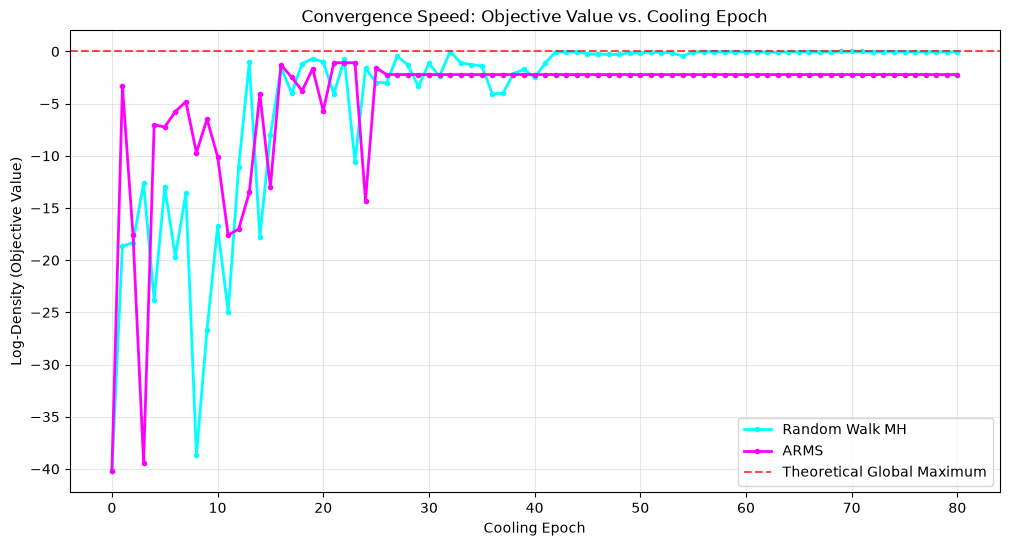

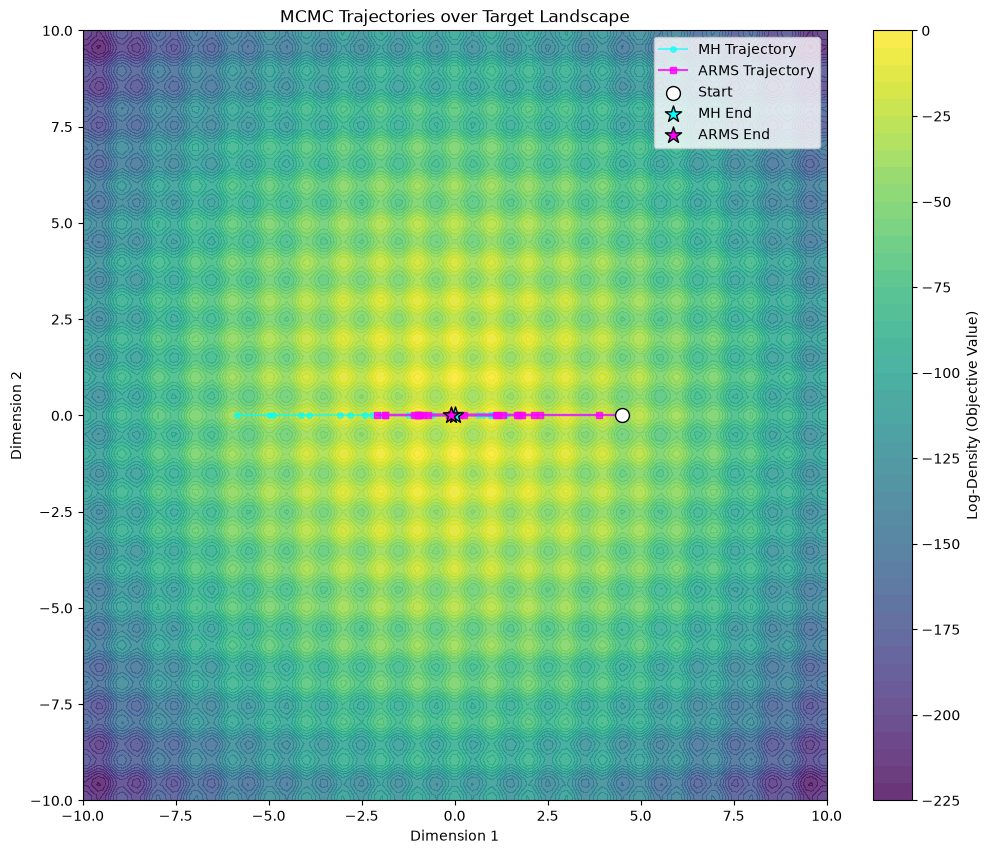

In [111]:
def run_full_benchmark_suite():
    """
    The master function that executes the optimization on a target function 
    and generates all analytical plots.
    """
    
    # 1. Select the target landscape 
    target_landscape = rastrigin_log_density
    
    # 2. Hyperparameters
    initial_state = np.array([4.5, ])  # Start far from the global max (0.0)
    T_initial = 20.0                 # High starting temperature for broad exploration
    epochs = 80                      # Number of cooling steps
    steps_per_epoch = 20             # MCMC transitions per temperature level
    
    # 3. Execute Random Walk MH with Simulated Annealing
    print("Running Random Walk MH + SA...")
    mh_best, mh_trajectory, mh_temps = simulated_annealing_optimizer(
        method='mh', initial_state=initial_state[0], base_log_density=target_landscape,
        num_epochs=epochs, steps_per_epoch=steps_per_epoch, T_init=T_initial,
        cooling_type='geometric', eta=0.92, mh_sigma=0.7
    )
    
    # 4. Execute ARMS with Simulated Annealing
    print("Running ARMS + SA...")
    arms_best, arms_trajectory, arms_temps = simulated_annealing_optimizer(
        method='arms', initial_state=initial_state[0], base_log_density=target_landscape,
        num_epochs=epochs, steps_per_epoch=steps_per_epoch, T_init=T_initial,
        cooling_type='geometric', eta=0.92, arms_points=6, arms_spread=4.0
    )
    
    mh_trajectory = np.insert(mh_trajectory, 0, initial_state)
    arms_trajectory = np.insert(arms_trajectory, 0, initial_state)

    print("\n--- Optimization Results ---")
    print(f"MH Final State:   {mh_trajectory[-1]:.4f} | Best Discovered: {mh_best:.4f}")
    print(f"ARMS Final State: {arms_trajectory[-1]:.4f} | Best Discovered: {arms_best:.4f}")
    
    # Generate the convergence speed graph
    plot_convergence_speed(mh_trajectory, arms_trajectory, target_landscape)
    
    # Generate the 2D Contour Map overlay
    plot_2d_contour_trajectory(target_landscape, mh_trajectory, arms_trajectory, bounds=(-10, 10))

run_full_benchmark_suite()

### Analyzing convergence with varying cooling schedules

Starting Systematic Cooling Schedule Grid Search on Rastrigin...

--- Geometric Cooling (Varying eta) ---
Method | eta   | Best State (x)  | Best Log-Density (h)
-------------------------------------------------------
MH     | 0.80  |        -0.0021 |             -0.0008
ARMS   | 0.80  |         0.0000 |             -0.0000
MH     | 0.85  |         0.0050 |             -0.0049
ARMS   | 0.85  |         0.0000 |             -0.0000
MH     | 0.90  |        -0.0026 |             -0.0013
ARMS   | 0.90  |        -0.0000 |             -0.0000
MH     | 0.92  |         0.0007 |             -0.0001
ARMS   | 0.92  |         0.0001 |             -0.0000
MH     | 0.95  |         0.0059 |             -0.0068
ARMS   | 0.95  |        -0.0004 |             -0.0000
MH     | 0.99  |        -0.0002 |             -0.0000
ARMS   | 0.99  |         0.0003 |             -0.0000

--- Logarithmic Cooling (Varying c) ---
Method | c     | Best State (x)  | Best Log-Density (h)
-------------------------------------

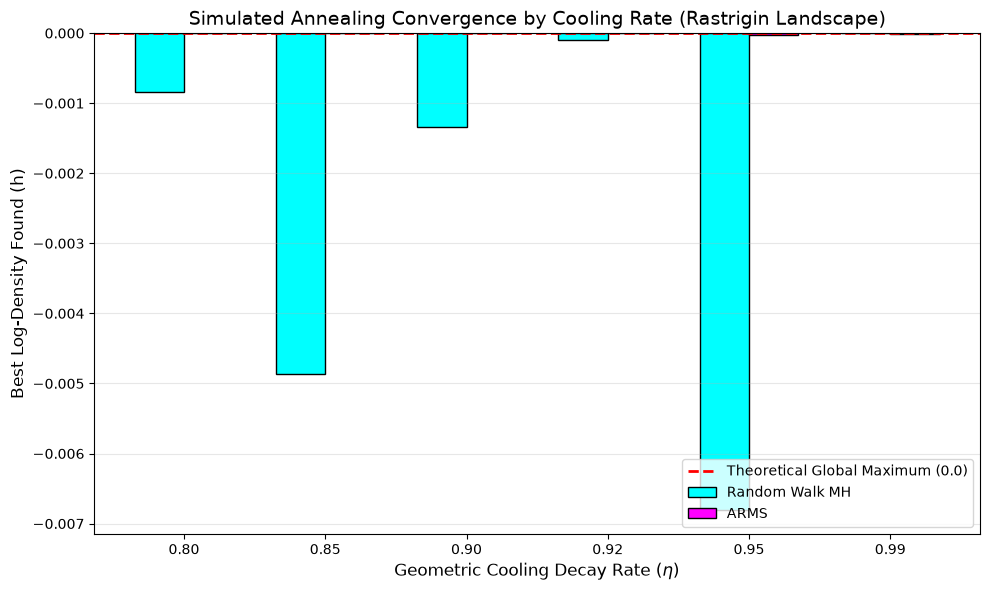

In [112]:
def run_cooling_schedule_grid_search():
    """
    Executes a grid search over cooling hyperparameters for both MH and ARMS,
    evaluating their performance on the Rastrigin landscape.
    """
    target_landscape = rastrigin_log_density
    initial_state = np.array([4.5])
    
    # SA Base Parameters
    T_init = 20.0
    epochs = 80
    steps_per_epoch = 15
    mh_sigma = 1.5
    
    # Grid of parameters to test (as specified in the interim report)
    eta_values = [0.80, 0.85, 0.90, 0.92, 0.95, 0.99]
    c_values = [1.0, 5.0, 10.0, 20.0]
    
    results = []
    
    print("Starting Systematic Cooling Schedule Grid Search on Rastrigin...\n")
    
    # 1. Test Geometric Cooling
    print("--- Geometric Cooling (Varying eta) ---")
    print(f"{'Method':<6} | {'eta':<5} | {'Best State (x)':<15} | {'Best Log-Density (h)':<20}")
    print("-" * 55)
    
    for eta in eta_values:
        for method in ['mh', 'arms']:
            best_state, _, _ = simulated_annealing_optimizer(
                method=method, 
                initial_state=initial_state[0], 
                base_log_density=target_landscape,
                num_epochs=epochs, 
                steps_per_epoch=steps_per_epoch, 
                T_init=T_init,
                cooling_type='geometric', 
                eta=eta, 
                mh_sigma=mh_sigma
            )
            
            # The optimizer returns the best_state; we recalculate the density for display
            best_density = target_landscape(best_state)
            
            results.append({
                'method': method,
                'cooling': 'geometric',
                'param_val': eta,
                'best_state': best_state,
                'best_density': best_density
            })
            print(f"{method.upper():<6} | {eta:<5.2f} | {best_state:>14.4f} | {best_density:>19.4f}")
    
    # 2. Test Logarithmic Cooling
    print("\n--- Logarithmic Cooling (Varying c) ---")
    print(f"{'Method':<6} | {'c':<5} | {'Best State (x)':<15} | {'Best Log-Density (h)':<20}")
    print("-" * 55)
    
    for c in c_values:
        for method in ['mh', 'arms']:
            best_state, _, _ = simulated_annealing_optimizer(
                method=method, 
                initial_state=initial_state[0], 
                base_log_density=target_landscape,
                num_epochs=epochs, 
                steps_per_epoch=steps_per_epoch, 
                T_init=T_init,
                cooling_type='logarithmic', 
                c=c, 
                mh_sigma=mh_sigma
            )
            
            best_density = target_landscape(best_state)
            
            results.append({
                'method': method,
                'cooling': 'logarithmic',
                'param_val': c,
                'best_state': best_state,
                'best_density': best_density
            })
            print(f"{method.upper():<6} | {c:<5.1f} | {best_state:>14.4f} | {best_density:>19.4f}")

    return results

def plot_geometric_grid_search(results):
    """
    Generates a grouped bar chart comparing the best density found by MH and ARMS
    across the different geometric cooling decay rates (eta).
    """
    # Filter for geometric results and extract unique eta values
    geo_results = [r for r in results if r['cooling'] == 'geometric']
    etas = sorted(list(set([r['param_val'] for r in geo_results])))
    
    # Extract the best densities aligned with the sorted etas
    mh_densities = [next(r['best_density'] for r in geo_results if r['method'] == 'mh' and r['param_val'] == e) for e in etas]
    arms_densities = [next(r['best_density'] for r in geo_results if r['method'] == 'arms' and r['param_val'] == e) for e in etas]
    
    x = np.arange(len(etas))
    width = 0.35
    
    plt.figure(figsize=(10, 6))
    
    # Plot bars
    plt.bar(x - width/2, mh_densities, width, label='Random Walk MH', color='cyan', edgecolor='black')
    plt.bar(x + width/2, arms_densities, width, label='ARMS', color='magenta', edgecolor='black')
    
    # Mark the theoretical global maximum
    plt.axhline(y=0.0, color='red', linestyle='--', linewidth=2, label='Theoretical Global Maximum (0.0)')
    
    # Formatting
    plt.xlabel(r'Geometric Cooling Decay Rate ($\eta$)', fontsize=12)
    plt.ylabel('Best Log-Density Found (h)', fontsize=12)
    plt.title('Simulated Annealing Convergence by Cooling Rate (Rastrigin Landscape)', fontsize=14)
    plt.xticks(x, [f"{e:.2f}" for e in etas])
    plt.legend(loc='lower right')
    plt.grid(True, alpha=0.3, axis='y')
    
    plt.tight_layout()
    plt.show()

# Run the grid search and plot the results
grid_results = run_cooling_schedule_grid_search()
plot_geometric_grid_search(grid_results)

### Multiple Seed Benchmarking

=== RWMH on Rastrigin ===
Running MH benchmark over 10 independent seeds...
Run 1/10 (Seed: 60227) | Final log-density: -0.000005 | State: -0.000151
Run 2/10 (Seed: 86837) | Final log-density: -0.000145 | State: 0.000855
Run 3/10 (Seed: 01738) | Final log-density: -0.000000 | State: 0.000022
Run 4/10 (Seed: 43015) | Final log-density: -0.000068 | State: -0.000586
Run 5/10 (Seed: 31705) | Final log-density: -0.000028 | State: 0.000379
Run 6/10 (Seed: 78729) | Final log-density: -0.000511 | State: -0.001605
Run 7/10 (Seed: 99163) | Final log-density: -0.000222 | State: 0.001058
Run 8/10 (Seed: 01571) | Final log-density: -0.000101 | State: 0.000714
Run 9/10 (Seed: 70678) | Final log-density: -0.000114 | State: 0.000757
Run 10/10 (Seed: 72153) | Final log-density: -0.000017 | State: 0.000291
--------------------------------------------------
MH Statistical Summary:
Mean log-density:   -0.000121 ± 0.000146
Median log-density: -0.000085
Global Best:        -0.000000 (Found at state: 0.00002

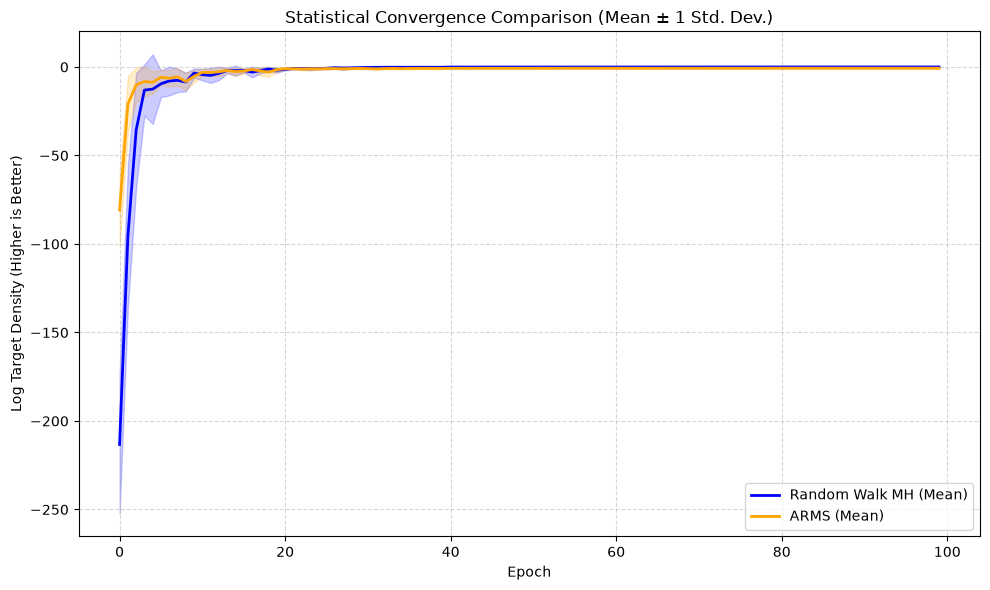

In [113]:
# 1. Run MH for 10 seeds
print("=== RWMH on Rastrigin ===")
mh_results = run_benchmark_with_seeds(
    method="mh", 
    num_seeds=10, 
    initial_state=18.0, 
    base_log_density=rastrigin_log_density,  # Must be passed explicitly like this
    num_epochs=100, 
    steps_per_epoch=15, 
    T_init=10.0, 
    cooling_type='geometric', 
    eta=0.90, 
    mh_sigma=1.0
)

# 2. Run ARMS for 10 seeds
print("=== ARMS on Rastrigin ===")
arms_results = run_benchmark_with_seeds(
    method="arms", 
    num_seeds=10, 
    initial_state=18.0, 
    base_log_density=rastrigin_log_density, 
    num_epochs=100, 
    steps_per_epoch=15, 
    T_init=10.0, 
    cooling_type='geometric', 
    eta=0.90, 
    arms_spread=10.0,
    arms_points=5
)

# 3. Plot the final statistical comparison
plot_statistical_convergence([mh_results, arms_results], labels=['Random Walk MH', 'ARMS'])

=== RWMH on Ackley ===
Running MH benchmark over 10 independent seeds...
Run 1/10 (Seed: 60227) | Final log-density: -19.338566 | State: 17.009437
Run 2/10 (Seed: 86837) | Final log-density: -0.000841 | State: 0.000210
Run 3/10 (Seed: 01738) | Final log-density: -0.009501 | State: -0.002305
Run 4/10 (Seed: 43015) | Final log-density: -0.000497 | State: 0.000124
Run 5/10 (Seed: 31705) | Final log-density: -0.005517 | State: -0.001355
Run 6/10 (Seed: 78729) | Final log-density: -0.007110 | State: 0.001737
Run 7/10 (Seed: 99163) | Final log-density: -0.009877 | State: 0.002393
Run 8/10 (Seed: 01571) | Final log-density: -1.351234 | State: -0.137878
Run 9/10 (Seed: 70678) | Final log-density: -0.001506 | State: -0.000375
Run 10/10 (Seed: 72153) | Final log-density: -0.011999 | State: 0.002889
--------------------------------------------------
MH Statistical Summary:
Mean log-density:   -2.073665 ± 5.768930
Median log-density: -0.008306
Global Best:        -0.000497 (Found at state: 0.00012

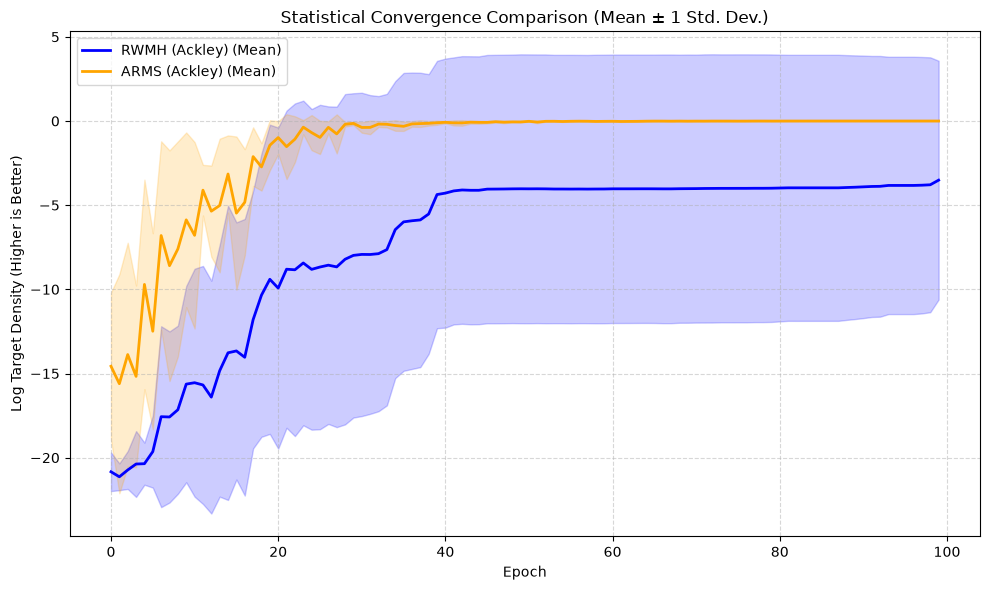

In [114]:
print("=== RWMH on Ackley ===")
mh_ackley = run_benchmark_with_seeds(
    method="mh", 
    num_seeds=10, 
    initial_state=18.0, 
    base_log_density=ackley_log_density, 
    num_epochs=100, 
    steps_per_epoch=15, 
    T_init=10.0, 
    cooling_type='geometric', 
    eta=0.90, 
    mh_sigma=1.0
)

print("=== ARMS on Ackley ===")
arms_ackley = run_benchmark_with_seeds(
    method="arms", 
    num_seeds=10, 
    initial_state=18.0, 
    base_log_density=ackley_log_density, 
    num_epochs=100, 
    steps_per_epoch=15, 
    T_init=10.0, 
    cooling_type='geometric', 
    eta=0.90, 
    arms_spread=10.0, 
    arms_points=5
)

# Plot the results
plot_statistical_convergence([mh_ackley, arms_ackley], labels=['RWMH (Ackley)', 'ARMS (Ackley)'])

=== RWMH on Gaussian Mixture ===
Running MH benchmark over 10 independent seeds...
Run 1/10 (Seed: 60227) | Final log-density: -2.009795 | State: 3.877682
Run 2/10 (Seed: 86837) | Final log-density: -1.794013 | State: -3.826991
Run 3/10 (Seed: 01738) | Final log-density: -1.753804 | State: -3.960114
Run 4/10 (Seed: 43015) | Final log-density: -1.753202 | State: -3.980615
Run 5/10 (Seed: 31705) | Final log-density: -1.753194 | State: -3.978803
Run 6/10 (Seed: 78729) | Final log-density: -1.753195 | State: -3.977874
Run 7/10 (Seed: 99163) | Final log-density: -2.009793 | State: 3.875799
Run 8/10 (Seed: 01571) | Final log-density: -1.753194 | State: -3.978583
Run 9/10 (Seed: 70678) | Final log-density: -1.754395 | State: -3.952693
Run 10/10 (Seed: 72153) | Final log-density: -1.753195 | State: -3.978824
--------------------------------------------------
MH Statistical Summary:
Mean log-density:   -1.808778 ± 0.101222
Median log-density: -1.753503
Global Best:        -1.753194 (Found at st

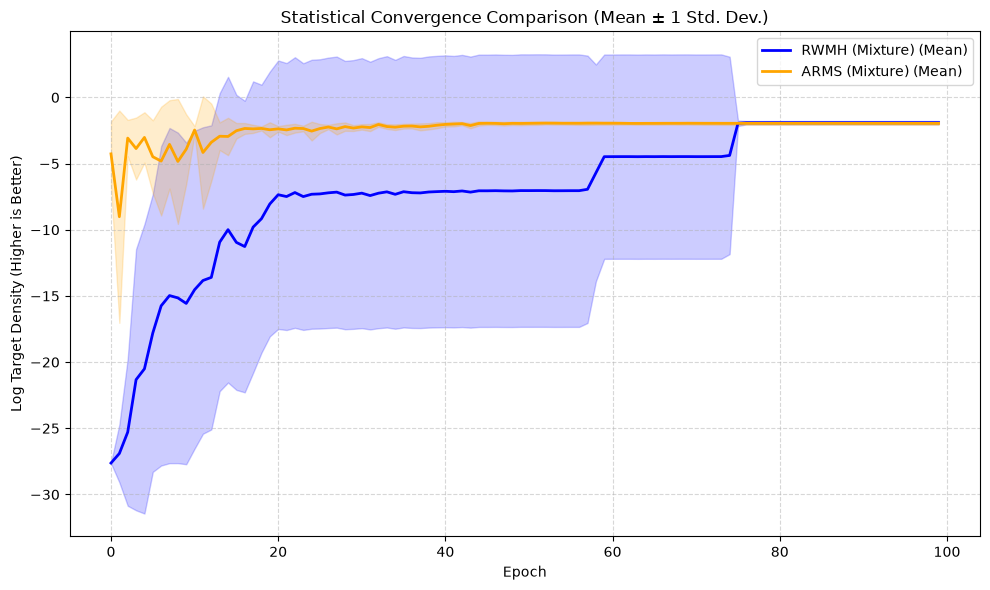

In [115]:
weights = [0.2, 0.5, 0.3]
means = [-4.0, 0.0, 4.0]
std_devs = [0.5, 2.0, 1.0]
def frozen_mixture(x):
    return gaussian_mixture_probability(x, weights, means, std_devs)
    
mixture_log_density = make_log_density(frozen_mixture)

print("=== RWMH on Gaussian Mixture ===")
mh_mixture = run_benchmark_with_seeds(
    method="mh", 
    num_seeds=10, 
    initial_state=18.0, 
    base_log_density=mixture_log_density, 
    num_epochs=100, 
    steps_per_epoch=15, 
    T_init=10.0, 
    cooling_type='geometric', 
    eta=0.90, 
    mh_sigma=1.0
)

print("=== ARMS on Gaussian Mixture ===")
arms_mixture = run_benchmark_with_seeds(
    method="arms", 
    num_seeds=10, 
    initial_state=18.0, 
    base_log_density=mixture_log_density, 
    num_epochs=100, 
    steps_per_epoch=15, 
    T_init=10.0, 
    cooling_type='geometric', 
    eta=0.90, 
    arms_spread=10.0, 
    arms_points=5
)

# Plot the results
plot_statistical_convergence([mh_mixture, arms_mixture], labels=['RWMH (Mixture)', 'ARMS (Mixture)'])

### A Real-World Bayesian Problem

=== Random Walk MH Benchmark (Bayesian Inference) ===
Starting sampler benchmark...
--------------------------------------------------
Sampling Efficiency Summary (ESS / Second)
--------------------------------------------------
Total Iterations:  50,000
Burn-in Discarded: 5,000
Acceptance Rate:   47.52%
Elapsed Time:      0.9010 seconds
Effective Samples: 10681.60 (out of 49,001)
ESS / Second:      11855.00
--------------------------------------------------
=== ARMS Benchmark (Bayesian Inference) ===
Starting sampler benchmark...
--------------------------------------------------
Sampling Efficiency Summary (ESS / Second)
--------------------------------------------------
Total Iterations:  50,000
Burn-in Discarded: 5,000
Acceptance Rate:   100.00%
Elapsed Time:      7.9325 seconds
Effective Samples: 61.06 (out of 49,001)
ESS / Second:      7.70
--------------------------------------------------


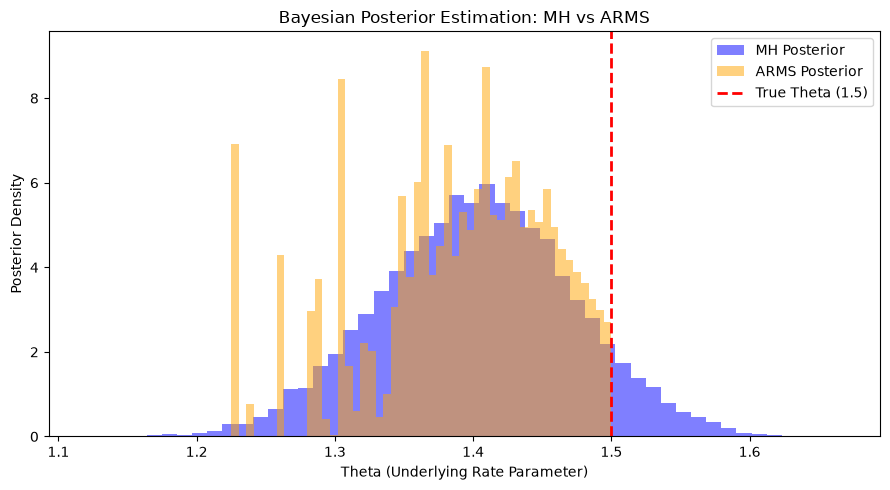

In [116]:
np.random.seed(67)
true_theta = 1.5  # The true hidden parameter we want the samplers to recover
# We observe 50 data points from the real world
observed_data = np.random.poisson(np.exp(true_theta), size=50)

def bayesian_poisson_log_posterior(theta):
    """
    Computes the unnormalized log posterior for our Bayesian model.
    Log Posterior = Log Likelihood + Log Prior.
    This function is strictly log-concave, making it the perfect target for ARMS!
    """
    # 1. Log Prior: theta ~ N(0, 10^2)
    # We ignore the normalizing constant since MCMC doesn't need it
    log_prior = -0.5 * (theta / 10.0)**2
    
    # 2. Log Likelihood: P(Y | theta)
    # For Poisson: log P(Y|lambda) = Y*log(lambda) - lambda
    # Since our rate lambda = exp(theta), log(lambda) = theta
    # We clip theta to prevent exponential overflow if the sampler wanders too far initially
    theta_clipped = np.clip(theta, -20, 20)
    rate = np.exp(theta_clipped)
    log_likelihood = np.sum(observed_data * theta_clipped - rate)
    
    return log_likelihood + log_prior

# Running the benchmarks
print("=== Random Walk MH Benchmark (Bayesian Inference) ===")
mh_ess, mh_ess_sec, mh_time, mh_samples = benchmark_sampler_ess(
    sampler_func=random_walk_mh,
    num_iterations=50000,
    burn_in=5000,
    initial_state=0.0, # Start at a bad guess (0) and let it find 1.5
    sigma=0.15,        # MH step size 
    log_target_density=bayesian_poisson_log_posterior
)
print("=== ARMS Benchmark (Bayesian Inference) ===")
arms_ess, arms_ess_sec, arms_time, arms_samples = benchmark_sampler_ess(
    sampler_func=arms_sampler,
    num_iterations=50000,
    burn_in=5000,
    initial_state=0.0,
    log_target_density=bayesian_poisson_log_posterior,
    arms_points=5,
    arms_spread=3
)

# Plotting
plt.figure(figsize=(9, 5))
plt.hist(mh_samples, bins=50, alpha=0.5, density=True, color='blue', label='MH Posterior')
plt.hist(arms_samples, bins=50, alpha=0.5, density=True, color='orange', label='ARMS Posterior')
plt.axvline(x=true_theta, color='red', linestyle='--', linewidth=2, label=f'True Theta ({true_theta})')
plt.title("Bayesian Posterior Estimation: MH vs ARMS")
plt.xlabel("Theta (Underlying Rate Parameter)")
plt.ylabel("Posterior Density")
plt.legend()
plt.tight_layout()
plt.show()

### An Interesting Finding

Interesting detail wherein the grid search implementation and setting the resolution to 10000 was giving much better results on everything for optimisation.

In [39]:
# Run Benchmark
print("=== RWMH on Rastrigin ===")
mh_results = run_benchmark_with_seeds(
    method="mh", 
    num_seeds=10, 
    initial_state=18.0, 
    base_log_density=rastrigin_log_density,  # Must be passed explicitly like this
    num_epochs=100, 
    steps_per_epoch=15, 
    T_init=10.0, 
    cooling_type='geometric', 
    eta=0.90, 
    mh_sigma=1.0
)

# Run Benchmark
print("=== ARMS on Rastrigin ===")
arms_results = run_benchmark_with_seeds(
    method="arms", 
    num_seeds=10, 
    initial_state=18.0, 
    base_log_density=rastrigin_log_density, 
    num_epochs=100, 
    steps_per_epoch=15, 
    T_init=10.0, 
    cooling_type='geometric', 
    eta=0.90, 
    arms_spread=10.0,
    arms_points=5
)

# Redefine sample_from_hull with 1000 resolution
def sample_from_hull(S, log_target_density, evaluate_hull, bounds=(-20, 20)):
    """
    Draws a candidate state x* from the exponentiated and normalized envelope exp(e_k(x)).
    Includes continuous jitter to solve the grid-blindness problem.
    """
    resolution = 1000
    
    # Create a fine grid over the search space
    x_grid = np.linspace(bounds[0], bounds[1], resolution)
    
    # Evaluate the hull e_k(x) at every point on the grid
    e_k_grid = np.array([evaluate_hull(x, S, log_target_density) for x in x_grid])
    
    # Exponentiate to get the unnormalized density envelope: exp(e_k(x))
    max_e_k = np.max(e_k_grid)
    env_density = np.exp(e_k_grid - max_e_k)
    
    # Normalize to create a valid Probability Density Function (PDF)
    pdf = env_density / np.sum(env_density)
    
    # Create the Cumulative Distribution Function (CDF)
    cdf = np.cumsum(pdf)
    
    # Draw a random uniform number and use inverse CDF to find the grid index
    u = np.random.uniform(0.0, 1.0)
    idx = min(np.searchsorted(cdf, u), len(x_grid) - 1)
    
    # Add continuous uniform jitter to break out of the fixed grid spacing.
    # This allows ARMS to explore continuous space and hit the microscopic SA peaks.
    step_size = (bounds[1] - bounds[0]) / (resolution - 1)
    jitter = np.random.uniform(-step_size / 2.0, step_size / 2.0)
    
    x_star = x_grid[idx] + jitter
    return x_star

# Run Benchmark
print("=== ARMS (1000 Resolution Grid) ===")
results_arms_1000 = run_benchmark_with_seeds(
    method="arms", 
    num_seeds=10, 
    initial_state=18.0, 
    base_log_density=rastrigin_log_density, 
    num_epochs=100, 
    steps_per_epoch=15, 
    T_init=10.0, 
    cooling_type='geometric', 
    eta=0.90, 
    arms_spread=10.0, 
    arms_points=5
)

# Redefine sample_from_hull with 10000 resolution
def sample_from_hull(S, log_target_density, evaluate_hull, bounds=(-20, 20)):
    """
    Draws a candidate state x* from the exponentiated and normalized envelope exp(e_k(x)).
    Includes continuous jitter to solve the grid-blindness problem.
    """
    resolution = 10000
    
    # Create a fine grid over the search space
    x_grid = np.linspace(bounds[0], bounds[1], resolution)
    
    # Evaluate the hull e_k(x) at every point on the grid
    e_k_grid = np.array([evaluate_hull(x, S, log_target_density) for x in x_grid])
    
    # Exponentiate to get the unnormalized density envelope: exp(e_k(x))
    max_e_k = np.max(e_k_grid)
    env_density = np.exp(e_k_grid - max_e_k)
    
    # Normalize to create a valid Probability Density Function (PDF)
    pdf = env_density / np.sum(env_density)
    
    # Create the Cumulative Distribution Function (CDF)
    cdf = np.cumsum(pdf)
    
    # Draw a random uniform number and use inverse CDF to find the grid index
    u = np.random.uniform(0.0, 1.0)
    idx = min(np.searchsorted(cdf, u), len(x_grid) - 1)
    
    # Add continuous uniform jitter to break out of the fixed grid spacing.
    # This allows ARMS to explore continuous space and hit the microscopic SA peaks.
    step_size = (bounds[1] - bounds[0]) / (resolution - 1)
    jitter = np.random.uniform(-step_size / 2.0, step_size / 2.0)
    
    x_star = x_grid[idx] + jitter
    return x_star

# Run Benchmark
print("=== ARMS (10000 Resolution Grid) ===")
results_arms_10000 = run_benchmark_with_seeds(
    method="arms", 
    num_seeds=10, 
    initial_state=18.0, 
    base_log_density=rastrigin_log_density, 
    num_epochs=100, 
    steps_per_epoch=15, 
    T_init=10.0, 
    cooling_type='geometric', 
    eta=0.90, 
    arms_spread=10.0, 
    arms_points=5
)

=== RWMH on Rastrigin ===
Running MH benchmark over 10 independent seeds...
Run 1/10 (Seed: 60227) | Final log-density: -0.000005 | State: -0.000151
Run 2/10 (Seed: 86837) | Final log-density: -0.000145 | State: 0.000855
Run 3/10 (Seed: 01738) | Final log-density: -0.000000 | State: 0.000022
Run 4/10 (Seed: 43015) | Final log-density: -0.000068 | State: -0.000586
Run 5/10 (Seed: 31705) | Final log-density: -0.000028 | State: 0.000379
Run 6/10 (Seed: 78729) | Final log-density: -0.000511 | State: -0.001605
Run 7/10 (Seed: 99163) | Final log-density: -0.000222 | State: 0.001058
Run 8/10 (Seed: 01571) | Final log-density: -0.000101 | State: 0.000714
Run 9/10 (Seed: 70678) | Final log-density: -0.000114 | State: 0.000757
Run 10/10 (Seed: 72153) | Final log-density: -0.000017 | State: 0.000291
--------------------------------------------------
MH Statistical Summary:
Mean log-density:   -0.000121 ± 0.000146
Median log-density: -0.000085
Global Best:        -0.000000 (Found at state: 0.00002

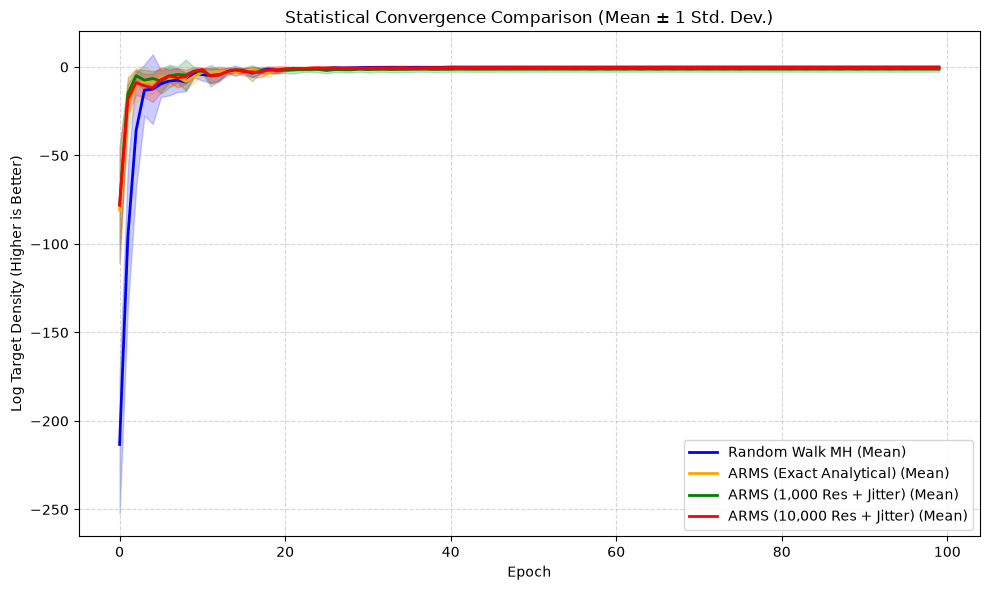

In [40]:
plot_statistical_convergence(
    [mh_results, arms_results, results_arms_1000, results_arms_10000], 
    labels=[
        'Random Walk MH', 
        'ARMS (Exact Analytical)', 
        'ARMS (1,000 Res + Jitter)', 
        'ARMS (10,000 Res + Jitter)'
    ]
)